# 04 — Model V2 Bowling Pressure Analysis

Analysis of V2 bowling rankings (`outputs/model_v2/` + `src/model_v2/`):
- Canonical Top-10 and all eligible bowlers (`Model B: Maintenance & Lift`, LPO + `pace_or_spin` + Elo controlled)
- Remediation of V1 issues: `Jasprit Bumrah` elite-baseline fix (`#2` vs V1 `#8`), Beta-binomial consistency shrinkage (`Sai Kishore`, `Sufiyan Muqeem`), and phase workload splits
- `Pace` vs `Spin` comparisons, `bowling_style_group` profiles, IPL vs T20I splits, and bootstrap rank uncertainty

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_v2').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

OUT_V2 = ROOT / 'outputs' / 'model_v2'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

## 1. Canonical Top-10 Bowlers & Eligible Pool Overview

In [2]:
top10_bowl = pd.read_csv(OUT_V2 / 'final_top10_bowlers.csv')
all_bowl = pd.read_csv(OUT_V2 / 'all_bowler_rankings.csv')
near_miss = pd.read_csv(OUT_V2 / 'near_miss_candidates.csv')

print(f'Eligible bowlers ranked: {len(all_bowl)} (canonical model: {top10_bowl["canonical_model"].iloc[0]})')
cols = ['rank', 'player_name', 'pace_or_spin', 'primary_bowling_type', 'tot_balls', 'hp_balls', 'pressure_neff',
        'hp_impact_24', 'norm_impact_24', 'maint_lift', 'eb_consistency', 'pressure_score',
        'boot_median_rank', 'boot_p05_rank', 'boot_p95_rank', 'top10_inclusion_frequency']
print(top10_bowl[cols].round(2).to_string(index=False))

Eligible bowlers ranked: 128 (canonical model: model_b)
 rank       player_name pace_or_spin   primary_bowling_type  tot_balls  hp_balls  pressure_neff  hp_impact_24  norm_impact_24  maint_lift  eb_consistency  pressure_score  boot_median_rank  boot_p05_rank  boot_p95_rank  top10_inclusion_frequency
    1      Sunil Narine         Spin     Right-arm offbreak       1530       454         739.59         11.52            3.78        8.79            0.71            2.48               4.0            1.0          13.00                       0.90
    2    Jasprit Bumrah         Pace         Right-arm Fast       1708       496         785.11         13.88            6.85        7.43            0.65            2.00               7.0            1.0          33.00                       0.66
    3 Mustafizur Rahman         Pace        Left-arm medium       1576       500         749.54         10.91            1.00        7.73            0.66            1.85              11.0            2.0       

## 2. V1-to-V2 Spotlight Bowlers & Near-Miss Pool

In [3]:
spot_bowl = ['Sunil Narine', 'Jasprit Bumrah', 'Sai Kishore', 'Sufiyan Muqeem', 'Varun Chakravarthy', 'Kuldeep Yadav', 'Mohit Sharma', 'Rashid Khan', 'Arshdeep Singh', 'Jofra Archer']
s_cols = ['rank', 'player_name', 'pace_or_spin', 'tot_balls', 'hp_balls', 'pressure_neff', 'hp_impact_24', 'norm_impact_24',
          'maint_lift', 'raw_consistency', 'eb_consistency', 'model_a_rank', 'model_b_rank', 'model_c_rank', 'practical_context_flag']
print('Spotlight bowlers in all_bowler_rankings:')
print(all_bowl[all_bowl['player_name'].isin(spot_bowl)].sort_values('rank')[s_cols].round(2).to_string(index=False))

bowl_nm = near_miss[near_miss['role'] == 'bowler'].copy()
print(f'\nBowler near-miss / ineligible candidates: {len(bowl_nm)}')
print(bowl_nm[['player_name', 'status', 'tot_balls', 'hp_balls', 'lp_balls', 'hp_matches', 'pressure_neff', 'metric_value', 'reason']].head(12).round(2).to_string(index=False))

Spotlight bowlers in all_bowler_rankings:
 rank        player_name pace_or_spin  tot_balls  hp_balls  pressure_neff  hp_impact_24  norm_impact_24  maint_lift  raw_consistency  eb_consistency  model_a_rank  model_b_rank  model_c_rank practical_context_flag
    1       Sunil Narine         Spin       1530       454         739.59         11.52            3.78        8.79             0.93            0.71             1             1             1   Active_IPL_2025_2026
    2     Jasprit Bumrah         Pace       1708       496         785.11         13.88            6.85        7.43             0.74            0.65             2             2             4   Active_IPL_2025_2026
    5       Mohit Sharma         Pace        649       277         370.57         11.50           -4.71        8.74             0.78            0.63             5             5            13   Active_IPL_2025_2026
    6        Sai Kishore         Spin        465       123         204.48         15.56           -2.7

## 3. Pace vs Spin Phase Profiles & Bootstrap Uncertainty

Eligible bowlers by style group:
pace_or_spin bowling_style_group  n_bowlers  median_score  mean_hp_impact_24  mean_death_share  mean_pp_share  top10_count
        Pace           Pace_Fast         24          0.22               5.38              0.28           0.43            2
        Pace     Pace_FastMedium         39         -0.10               3.27              0.30           0.38            3
        Pace         Pace_Medium         20         -0.15               2.81              0.29           0.35            1
        Spin         Spin_Finger         24         -0.14               2.97              0.09           0.23            3
        Spin          Spin_Wrist         21         -0.09               2.29              0.14           0.06            1


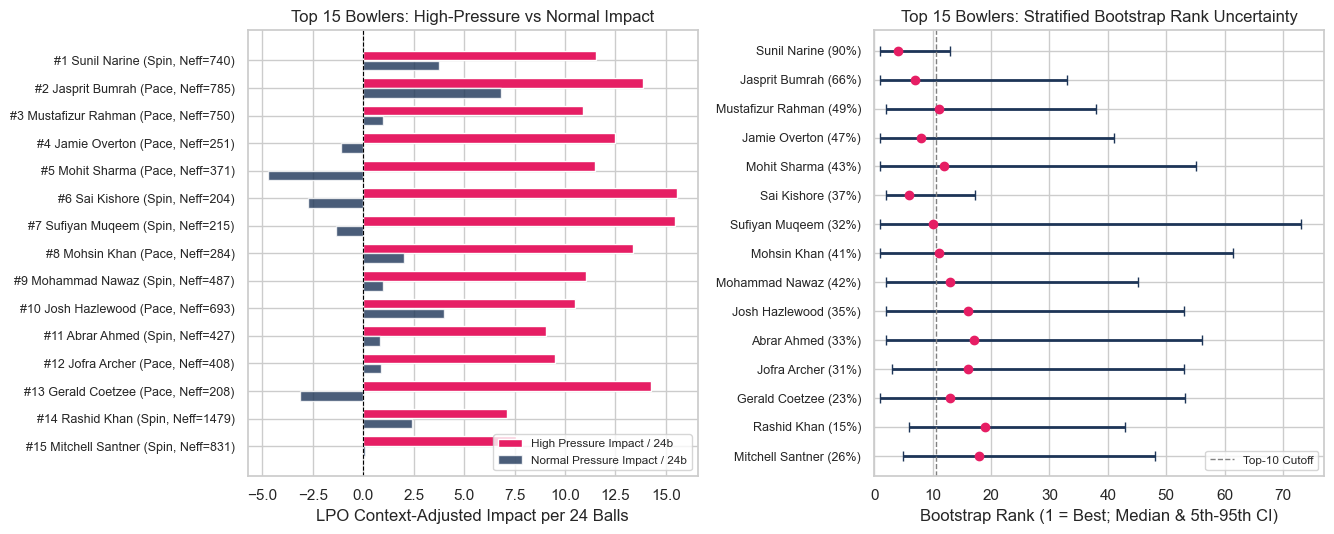

In [4]:
style_summary = (
    all_bowl.groupby(['pace_or_spin', 'bowling_style_group'])
    .agg(
        n_bowlers=('bowler_id', 'count'),
        median_score=('pressure_score', 'median'),
        mean_hp_impact_24=('hp_impact_24', 'mean'),
        mean_death_share=('death_share', 'mean'),
        mean_pp_share=('pp_share', 'mean'),
        top10_count=('rank', lambda s: int((s <= 10).sum())),
    )
    .reset_index()
)
print('Eligible bowlers by style group:')
print(style_summary.round(2).to_string(index=False))

top15 = all_bowl.head(15).copy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
y = np.arange(len(top15))[::-1]
labels = [f"#{int(r.rank)} {r.player_name} ({r.pace_or_spin}, Neff={r.pressure_neff:.0f})" for r in top15.itertuples()]
axes[0].barh(y + 0.18, top15['hp_impact_24'], height=0.35, color='#E61E64', label='High Pressure Impact / 24b')
axes[0].barh(y - 0.18, top15['norm_impact_24'], height=0.35, color='#1D3557', alpha=0.8, label='Normal Pressure Impact / 24b')
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=9)
axes[0].set_xlabel('LPO Context-Adjusted Impact per 24 Balls')
axes[0].set_title('Top 15 Bowlers: High-Pressure vs Normal Impact')
axes[0].legend(loc='lower right', fontsize=8.5)

med = top15['boot_median_rank']
err_low = np.maximum(0.0, med - top15['boot_p05_rank'])
err_high = np.maximum(0.0, top15['boot_p95_rank'] - med)
axes[1].errorbar(med, y, xerr=[err_low, err_high], fmt='o', color='#E61E64', ecolor='#1D3557', elinewidth=2, capsize=3.5)
axes[1].axvline(10.5, color='gray', linestyle='--', linewidth=1, label='Top-10 Cutoff')
axes[1].set_yticks(y)
axes[1].set_yticklabels([f"{r.player_name} ({100*r.top10_inclusion_frequency:.0f}%)" for r in top15.itertuples()], fontsize=9)
axes[1].set_xlim(0, max(75, float(top15['boot_p95_rank'].max()) + 4))
axes[1].set_xlabel('Bootstrap Rank (1 = Best; Median & 5th-95th CI)')
axes[1].set_title('Top 15 Bowlers: Stratified Bootstrap Rank Uncertainty')
axes[1].legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()